# NMF Practical Work

### Student - Guilherme Lorete Schmidt

Telecom Paris - APM_4AI04_TP

## Introduction

In this practical work, we will deal with non-negative matrix factorization (NMF) with the $\beta$-divergence. To this end, the multiplicative update rules (MUR) algorithm will be implemented, alongside its source reconstruction algorithm.

We then apply the algorithm on an audio file where a piano plays 8 notes separately and then a chord, seeking to evaluate the algorithm's effectiveness.

To start, we load libraries and load the audio file, displaying its characteristics.

In [28]:
%matplotlib inline

In [109]:
import numpy as np

# matplotlib for displaying the output
import matplotlib.pyplot as plt
import matplotlib.style as ms

# and IPython.display for audio output
import IPython.display as ipd

# Librosa for audio
import librosa
# # And the display module for visualization
import librosa.display


<Figure size 432x288 with 0 Axes>

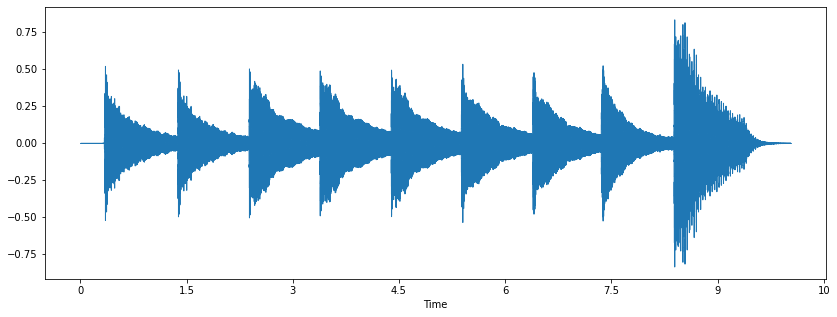

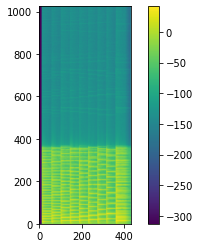

In [66]:
# Audio file
fname = 'Cmajor_piano8khz.wav'

# Load signal
y, sr = librosa.load(fname)

# Compute STFT
Xstft = librosa.stft(y, n_fft=2048, hop_length=512, win_length=None)
X = np.abs(Xstft)

# Visualize the waveform
plt.figure()
plt.figure(figsize=(14, 5))
librosa.display.waveshow(y, sr=sr)

# Visualize the spectrum
plt.figure()
plt.imshow(20*np.log10(np.abs(X)+ np.finfo(float).eps), origin="lower")
plt.colorbar()

display(ipd.Audio(y, rate=sr))


## 1. By following the technique that we used in the lecture, derive the MUR algorithm by yourselves

As a first step in the MUR implementation, we derive the update rules.

We start the derivation by stating the problem we wish to solve:

$$
(W^*, H^*) = \argmin_{W \ge 0, H\ge 0} \sum^I_{i=1} \sum^J_{j=1} d_\beta (x_{ij} || \hat{x}_ij)
$$

Where the $\beta$-divergence function $d_\beta$ is defined as:

$$
d_\beta (x_{ij} || \hat{x}_ij) = \dfrac{x^\beta}{\beta (\beta-1)} - \dfrac{x \hat{x}^{\beta-1}}{\beta - 1} + \dfrac{\hat{x}^\beta}{\beta}
$$

and

$$
\hat{x}_{ij} = \sum_k w_{ik} h_{kj}
$$

For the minimization of this objective function we will use gradient descent. To start, we derive the expression of the gradient with respect to $W$ and to $H$. Since

$$
\dfrac{\partial}{\partial w_{ik}} \hat{x}_{ij} = \dfrac{\partial}{\partial w_{ik}} \sum_{k'} w_{ik'} h_{k'j} = h_{kj} \quad \text{and} \quad \dfrac{\partial}{\partial h_{kj}} \hat{x}_{ij} = w_{ik}
$$

we have that

$$
\dfrac{\partial}{\partial w_{ik}} \sum^I_{i=1} \sum^J_{j=1} \left( \dfrac{x_{ij}^\beta}{\beta (\beta-1)} - \dfrac{x_{ij} \hat{x}_{ij}^{\beta-1}}{\beta - 1} + \dfrac{\hat{x}_{ij}^\beta}{\beta} \right) = \sum^J_{j=1} \left( \hat{x}_{ij}^{\beta - 1} - x_{ij} \hat{x}_{ij}^{\beta - 2} \right) h_{kj}
$$

$$
\dfrac{\partial}{\partial h_{kj}} \sum^I_{i=1} \sum^J_{j=1} \left( \dfrac{x_{ij}^\beta}{\beta (\beta-1)} - \dfrac{x_{ij} \hat{x}_{ij}^{\beta-1}}{\beta - 1} + \dfrac{\hat{x}_{ij}^\beta}{\beta} \right) = \sum^I_{i=1} w_{ik}  \left( \hat{x}_{ij}^{\beta - 1} - x_{ij} \hat{x}_{ij}^{\beta - 2} \right)
$$

Representing the result in matrix form for easier visualization (where $f_o$ is the objective function), it is

$$
\nabla_W f_o = \left( \hat{X}^{\beta - 1} - X \circ \hat{X}^{\beta - 2} \right) H^T
$$

$$
\nabla_H f_o = W^T \left( \hat{X}^{\beta - 1} - X \circ \hat{X}^{\beta - 2} \right)
$$

Therefore, the gradient descent step is given by. Since the step occurs independently for each element of the matrix, $\eta_W$ and $\eta_H$ are matrices of the same size as $W$ and $H$, respectively:

$$
W \longleftarrow W - \eta_W \circ \left( \hat{X}^{\beta - 1} - X \circ \hat{X}^{\beta - 2} \right) H^T
$$

$$
H \longleftarrow H - \eta_H \circ W^T \left( \hat{X}^{\beta - 1} - X \circ \hat{X}^{\beta - 2} \right)
$$

To make the update rule multiplicative and to guarantee the positivity of $W$ and $H$, we then choose $\eta_W$ and $\eta_H$ such that

$$
W - \eta_W \circ \hat{X}^{\beta - 1} H^T = 0
$$

$$
H - \eta_H \circ W^T \hat{X}^{\beta - 1} = 0
$$

Giving us (considering the division as element by element):

$$
\eta_W = \dfrac{W}{\hat{X}^{\beta - 1} H^T}
$$

$$
\eta_H = \dfrac{H}{W^T \hat{X}^{\beta - 1}}
$$

And thus, substituting $\eta_W$ and $\eta_H$ in the gradient descent, we get the expected result:

$$
W \longleftarrow W \circ \dfrac{(X \circ \hat{X}^{\beta - 2}) H^T }{\hat{X}^{\beta - 1} H^T}
$$

$$
H \longleftarrow H \circ \dfrac{ W^T (X \circ \hat{X}^{\beta - 2}) }{ W^T \hat{X}^{\beta - 1} }
$$


## 2. Implement MUR for NMF with beta-divergence 

Below we implement the function `MUR_step` that performs a single step of the MUR algorithm, based on the equation derived in the previous question.

In [31]:
def MUR_step(W, H, X, beta):
    # Calculates X hat
    X_hat = W @ H

    # Perform W step
    top_W = (X * (X_hat ** (beta - 2))) @ H.T
    bottom_W = X_hat ** (beta - 1) @ H.T
    new_W = W * (top_W / bottom_W) + np.finfo(float).eps

    # Calculates new X hat
    X_hat = new_W @ H

    # Preform H step
    top_H = new_W.T @ (X * (X_hat ** (beta - 2)))
    bottom_H = new_W.T @ X_hat ** (beta - 1)
    new_H = H * (top_H / bottom_H) + np.finfo(float).eps

    return new_W, new_H

def MUR(X, iterations, beta, dim):
    # Initializes W and H matrices
    lin = X.shape[0]
    col = X.shape[1]
    W = np.random.rand(lin, dim) + np.finfo(float).eps
    H = np.random.rand(dim, col) + np.finfo(float).eps

    # Performs MUR iterations
    for i in range(iterations):
        W, H = MUR_step(W, H, X, beta)

    return W, H

We then define a function to plot the matrices $W$, $H$ and $\hat{X}$ simultaneously.

In [61]:
def plot_hat(W, H):
    fig = plt.figure(figsize=(12, 8))
    gs = fig.add_gridspec(
        2, 2, 
        height_ratios=[1, 3],
        width_ratios=[1, 3],
        wspace=0.25,
        hspace=0.2
    )
    ax_W = fig.add_subplot(gs[1, 0])
    ax_H = fig.add_subplot(gs[0, 1])
    ax_X = fig.add_subplot(gs[1, 1])

    # Plot W
    im_W = ax_W.imshow(20*np.log10(np.abs(W)), aspect='auto', interpolation='nearest')
    ax_W.set_title("W")
    ax_W.set_ylabel("Frequency bin")
    fig.colorbar(im_W, ax=ax_W, fraction=0.05, pad=0.05)

    # Plot H
    im_H = ax_H.imshow(20*np.log10(np.abs(H)), aspect='auto', interpolation='nearest')
    ax_H.set_title("H")
    ax_H.xaxis.tick_top()
    fig.colorbar(im_H, ax=ax_H, fraction=0.02, pad=0.02)

    # Plot X_hat
    X_hat = W @ H
    im_X = ax_X.imshow(20*np.log10(np.abs(X_hat)), aspect='auto', interpolation='nearest')
    ax_X.set_title(r"$\hat{X}$")
    ax_X.set_xlabel("Time bin")
    fig.colorbar(im_X, ax=ax_X, fraction=0.02, pad=0.02)

    plt.show()

Below we perform the test of the MUR algorithm, choosing $8$ dimensions for $W$ and $H$.

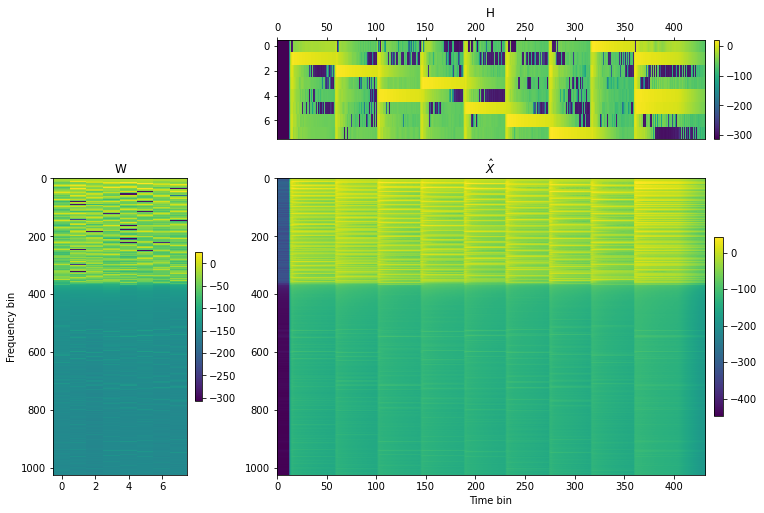

In [64]:
# Defines test values for the algorithm
iterations = 1000
beta = 1
dimensions = 8
# Runs algorithm
W, H = MUR(X, iterations, beta, dimensions)
plot_hat(W, H)

# Reconstructs the audio (considering phase information)
display(ipd.Audio(librosa.istft(W @ H * np.exp(1j * np.angle(Xstft)), hop_length=hop_length, win_length=win_length, length=len(y)), rate=sr))

Observing the result, the $H$ matrix shows 8 clearly defined notes played in sequence, followed by a chord combining 3 notes, which perfectly corresponds to what is heard in the audio. Even if there is some interference between the notes, the dominant note at each instant is clear. 

Listening to the audio generated from $\hat{X}$, it closely follows the input audio, with no significant deviations. We underline that we applied the phase information of the source on top of the reconstructed $\hat{X}$, otherwise the audio would present significant distortions.

This shows that the MUR implementation performs as expected in the separation of the notes and that the $W$ and $H$ matrices represent with precision the source data.

## 3. Experiment with the algorithm parameters, such as $\beta$, number of columns in $W$, STFT window size, hop size, etc. 

At each subsection below we vary a single parameter, only varying others when strictly necessary to guarantee valid results.

### 3.1 Varying $\beta$

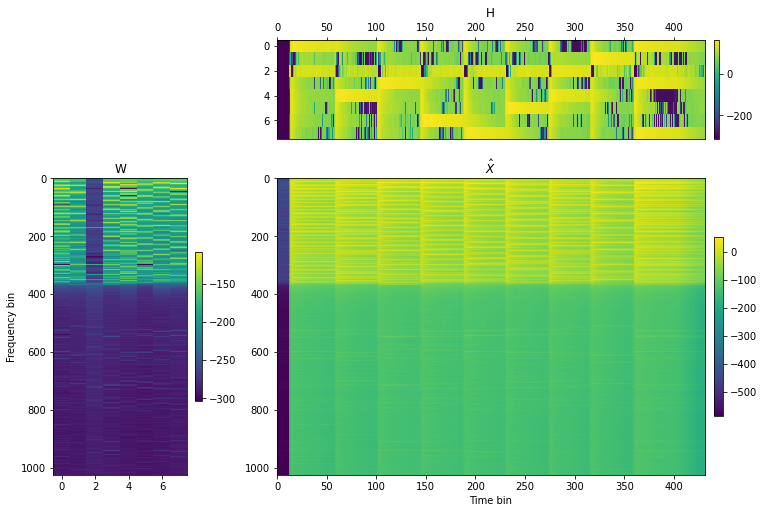

In [114]:
# Defines values for the algorithm
iterations = 800
beta = 0
dimensions = 8
win_length = 2048
hop_length = 512
# Compute STFT
Xstft = librosa.stft(y, n_fft=2048, hop_length=hop_length, win_length=win_length)
X = np.abs(Xstft)
# Runs algorithm
W, H = MUR(X, iterations, beta, dimensions)
plot_hat(W, H)
display(ipd.Audio(librosa.istft(W @ H * np.exp(1j * np.angle(Xstft)), hop_length=hop_length, win_length=win_length, length=len(y)), rate=sr))

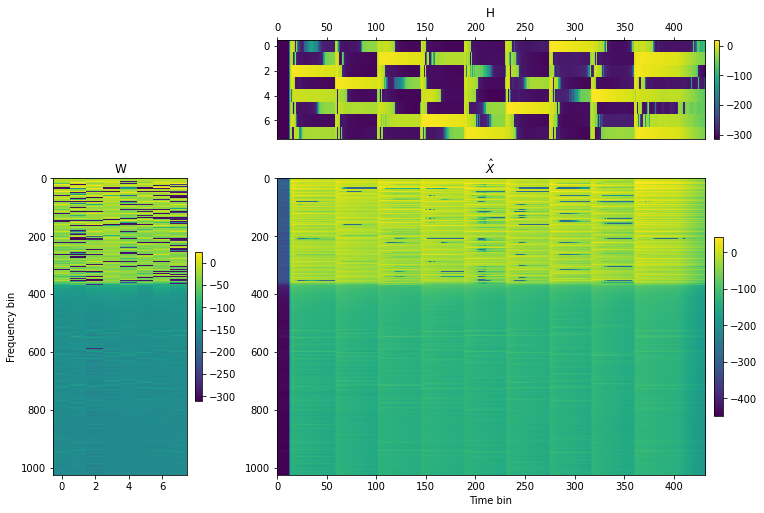

In [108]:
# Defines values for the algorithm
iterations = 1000
beta = 2
dimensions = 8
win_length = 2048
hop_length = 512
# Compute STFT
Xstft = librosa.stft(y, n_fft=2048, hop_length=hop_length, win_length=win_length)
X = np.abs(Xstft)
# Runs algorithm
W, H = MUR(X, iterations, beta, dimensions)
plot_hat(W, H)
display(ipd.Audio(librosa.istft(W @ H * np.exp(1j * np.angle(Xstft)), hop_length=hop_length, win_length=win_length, length=len(y)), rate=sr))

For $\beta = 0$, the algorithm uses Itakura-Saito Divergence. It produces mediocre results, properly reproducing some notes but completely failing on others. Even increasing the number of iterations the algorithm was not able to converge.

Using Kullback-Leibler Divergence when $\beta = 1$ (as shown in the previous section), it provides generally the best and most faithful results.

At last, when $\beta = 2$ and the algorithm uses Euclidian Distance, it generates a good reproduction. We can also observe that there seems to be a greater gap between loud notes and silences, as seen in matrix $H$. It also seems to ignore more subtle frequencies, putting their intensity at $0$, as seen in $W$.

### 3.2 Varying window size

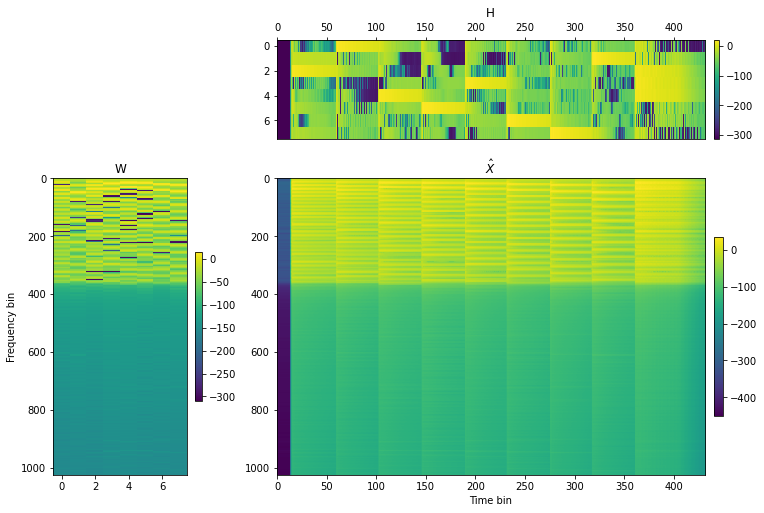

In [106]:
# Defines values for the algorithm
iterations = 500
beta = 1
dimensions = 8
win_length = 768
hop_length = 512
# Compute STFT
Xstft = librosa.stft(y, n_fft=2048, hop_length=hop_length, win_length=win_length)
X = np.abs(Xstft)
# Runs algorithm
W, H = MUR(X, iterations, beta, dimensions)
plot_hat(W, H)
display(ipd.Audio(librosa.istft(W @ H * np.exp(1j * np.angle(Xstft)), hop_length=hop_length, win_length=win_length, length=len(y)), rate=sr))

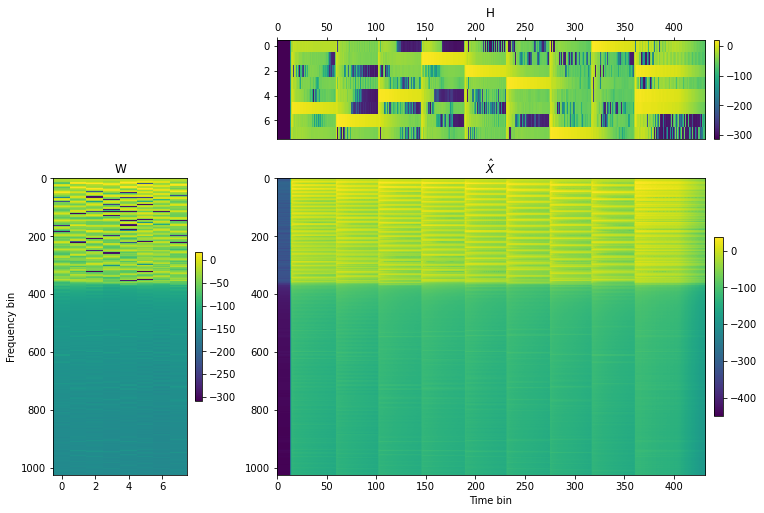

In [101]:
# Defines values for the algorithm
iterations = 500
beta = 1
dimensions = 8
win_length = 1024
hop_length = 512
# Compute STFT
Xstft = librosa.stft(y, n_fft=2048, hop_length=hop_length, win_length=win_length)
X = np.abs(Xstft)
# Runs algorithm
W, H = MUR(X, iterations, beta, dimensions)
plot_hat(W, H)
display(ipd.Audio(librosa.istft(W @ H * np.exp(1j * np.angle(Xstft)), hop_length=hop_length, win_length=win_length, length=len(y)), rate=sr))

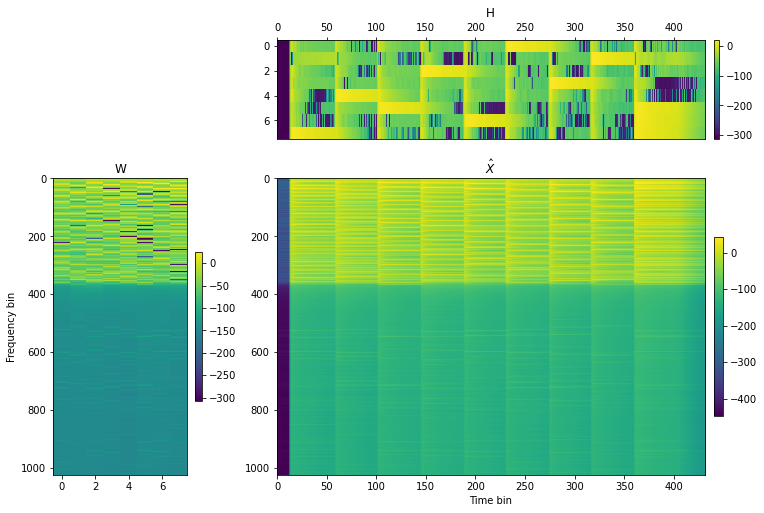

In [103]:
# Defines values for the algorithm
iterations = 500
beta = 1
dimensions = 8
win_length = 2048
hop_length = 512
# Compute STFT
Xstft = librosa.stft(y, n_fft=2048, hop_length=hop_length, win_length=win_length)
X = np.abs(Xstft)
# Runs algorithm
W, H = MUR(X, iterations, beta, dimensions)
plot_hat(W, H)
display(ipd.Audio(librosa.istft(W @ H * np.exp(1j * np.angle(Xstft)), hop_length=hop_length, win_length=win_length, length=len(y)), rate=sr))

This parameter represents a trade-off between frequency and time resolution. However, observe that since neither `n_fft` nor `hop_length` were changed, the matrices remain the same size.

What we see is that if the window length decreases, the horizontal lines in the $W$ matrix become larger, "blurring" the frequency. At the same time, the time measurements at $H$ gain precision.

Increasing the window length has the reverse effect, making the frequencies at $W$ more fine, but blurring the time at $H$. At some point, it may even be difficult to distinguish the moment at which the hammer strikes the cord on the piano, for example. Using window lengths beyond 3000 the algorithm even failed to properly reconstruct the audio.

### 3.3 Varying hop size

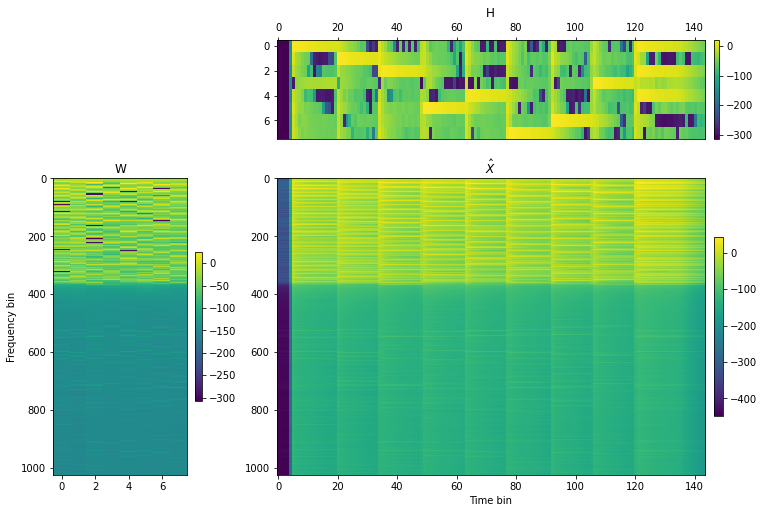

In [86]:
# Defines values for the algorithm
iterations = 1000
beta = 1
dimensions = 8
win_length = 2048
hop_length = 1536
# Compute STFT
Xstft = librosa.stft(y, n_fft=2048, hop_length=hop_length, win_length=win_length)
X = np.abs(Xstft)
# Runs algorithm
W, H = MUR(X, iterations, beta, dimensions)
plot_hat(W, H)
display(ipd.Audio(librosa.istft(W @ H * np.exp(1j * np.angle(Xstft)), hop_length=hop_length, win_length=win_length, length=len(y)), rate=sr))

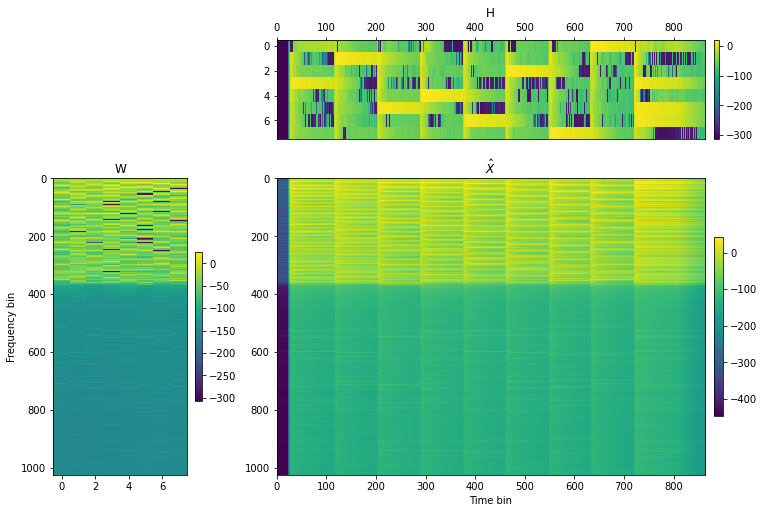

In [78]:
# Defines values for the algorithm
iterations = 1000
beta = 1
dimensions = 8
win_length = 2048
hop_length = 256
# Compute STFT
Xstft = librosa.stft(y, n_fft=2048, hop_length=hop_length, win_length=win_length)
X = np.abs(Xstft)
# Runs algorithm
W, H = MUR(X, iterations, beta, dimensions)
plot_hat(W, H)
display(ipd.Audio(librosa.istft(W @ H * np.exp(1j * np.angle(Xstft)), hop_length=hop_length, win_length=win_length, length=len(y)), rate=sr))

The small hop size of 256 promoted a high quality and fluid audio reconstruction. However, it significantly increased the computation time of the MUR algorithm, since the matrices involved are larger.

The big hop size of 1536, while greatly speeding up the MUR algorithm, generates a low quality audio reconstruction, being choppy and showing random clicks and variations in the sound.

### 3.4 Varying number of columns in $W$

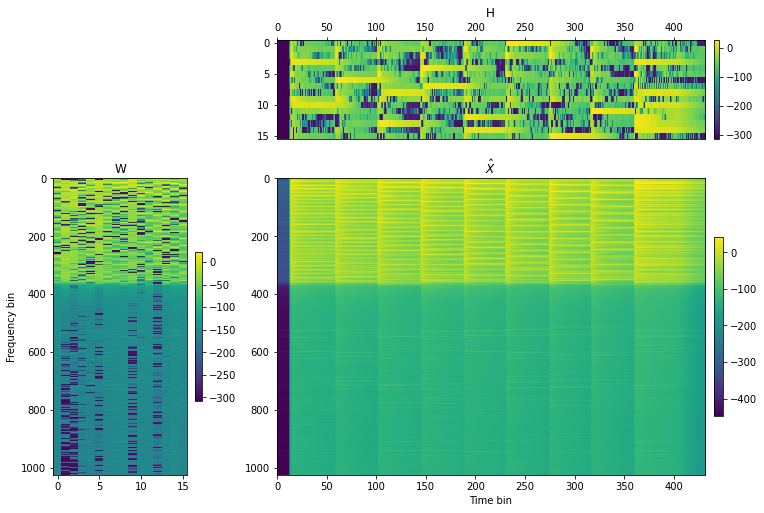

In [75]:
# Defines values for the algorithm
iterations = 500
beta = 1
dimensions = 16
win_length = 2048
hop_length = 512
# Compute STFT
Xstft = librosa.stft(y, n_fft=2048, hop_length=hop_length, win_length=win_length)
X = np.abs(Xstft)
# Runs algorithm
W, H = MUR(X, iterations, beta, dimensions)
plot_hat(W, H)
display(ipd.Audio(librosa.istft(W @ H * np.exp(1j * np.angle(Xstft)), hop_length=hop_length, win_length=win_length, length=len(y)), rate=sr))

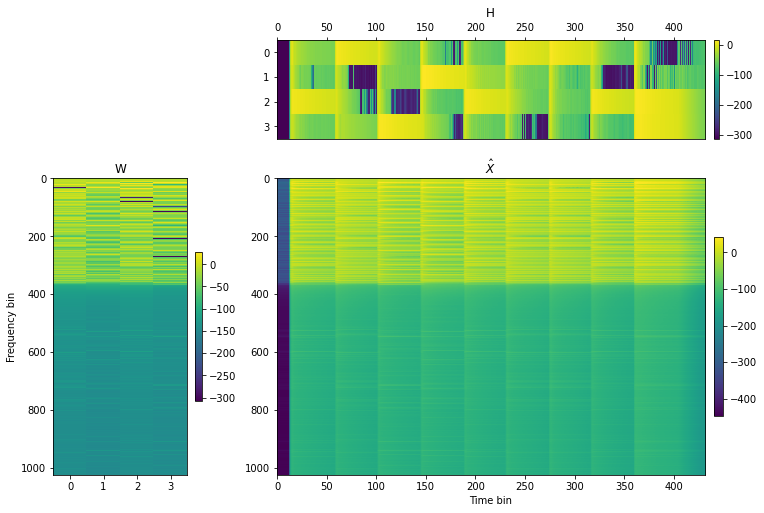

In [76]:
# Defines values for the algorithm
iterations = 500
beta = 1
dimensions = 4
win_length = 2048
hop_length = 512
# Compute STFT
Xstft = librosa.stft(y, n_fft=2048, hop_length=hop_length, win_length=win_length)
X = np.abs(Xstft)
# Runs algorithm
W, H = MUR(X, iterations, beta, dimensions)
plot_hat(W, H)
display(ipd.Audio(librosa.istft(W @ H * np.exp(1j * np.angle(Xstft)), hop_length=hop_length, win_length=win_length, length=len(y)), rate=sr))

When the number of columns of $W$ is below 8, the algorithm is forced to group multiple notes together in a single column, as can be seen in the $W$ matrix. In addition, instead of each note being played separately, they are played multiple times, as shown in $H$. At last, we can hear in the resulting audio that most notes turn into chords.

On the other hand, when adopting 16 columns, the algorithm is capable of faithfully reconstructing the source audio. However, we observe that each note is split into multiple dimensions instead of being grouped together into a single column of $W$. Thus, even if a single note is being played in the audio, multiple components are active in $H$.

## 4. Reconstruct each musical note separately


At last, we implement the source reconstruction algorithm, defined by:

$$
X_i = X \circ \dfrac{W(:,i) H(i,:)}{W H}
$$

In [ ]:
def reconstruct(X, W, H):
    X_reconstructed = []
    for i in range(W.shape[1]):
        result = X * (W[:,i].reshape((W.shape[0],1)) @ H[i].reshape((1,H.shape[1]))) / (W @ H)
        X_reconstructed.append(result)
    return np.array(X_reconstructed)

Then, we run the MUR algorithm using ideal parameters, reconstructing each musical note from the $W$ and $H$ matrices thus generated.

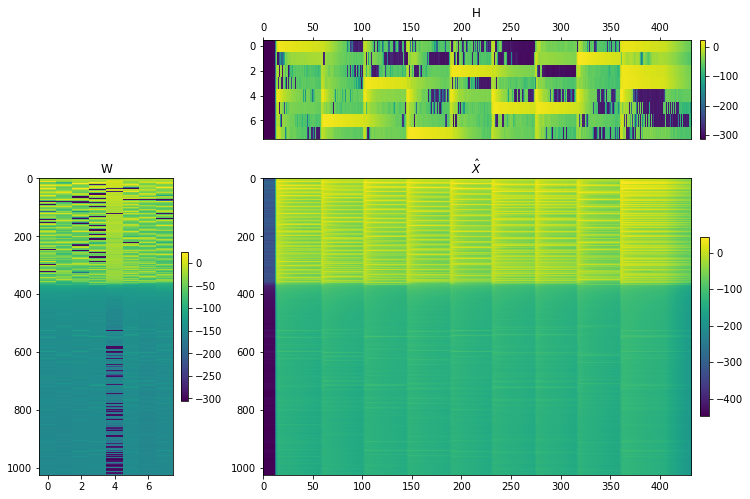

In [51]:
# Defines ideal parameters for the algorithm
iterations = 1000
beta = 1
dimensions = 8
win_length = 2048
hop_length = 512
# Compute STFT
Xstft = librosa.stft(y, n_fft=2048, hop_length=hop_length, win_length=win_length)
X = np.abs(Xstft)
# Runs algorithm
W, H = MUR(X, iterations, beta, dimensions)
plot_hat(W, H)

# Reconstructs musical notes
X_reconstructed = reconstruct(Xstft, W, H)

To finalize, we plot each musical note's spectrum and their audio. Note that they are chronologically unordered.

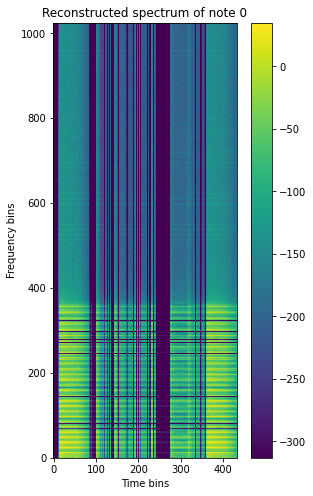

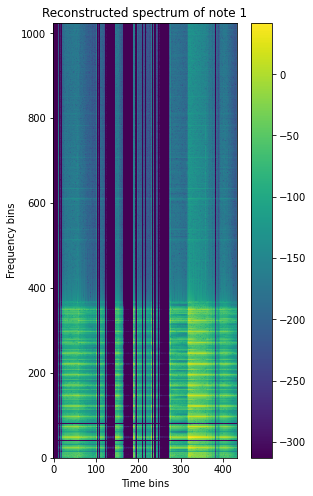

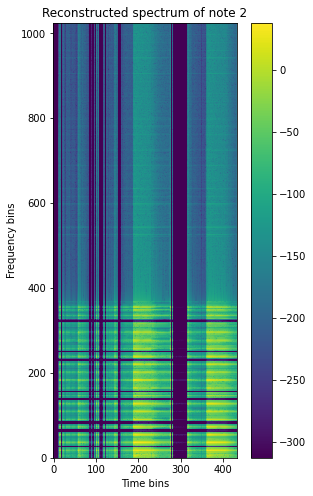

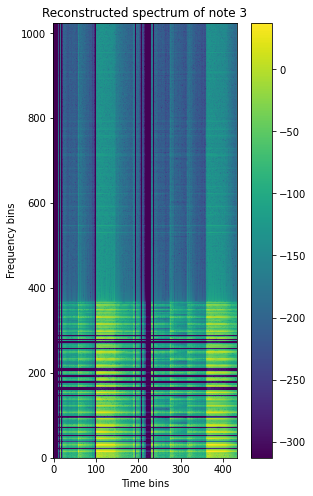

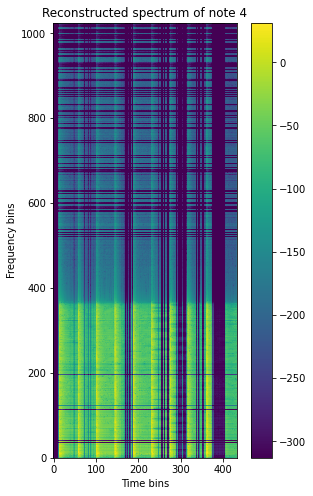

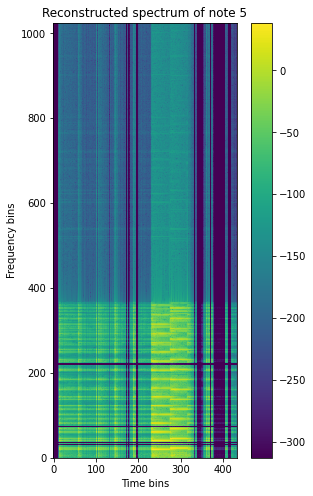

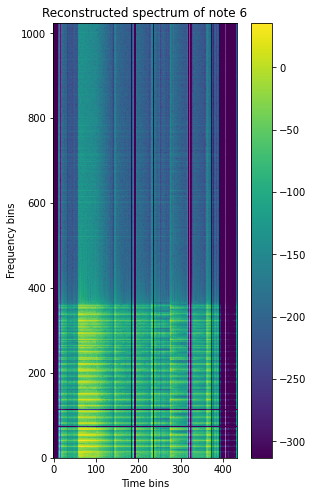

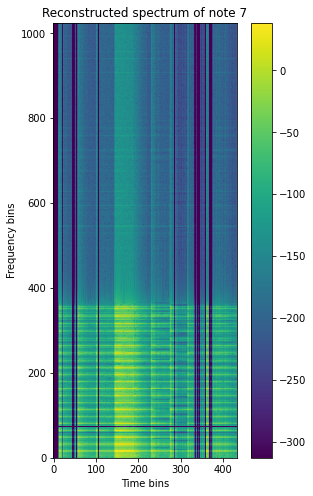

In [ ]:
y_hat = []
for i in range(X_reconstructed.shape[0]):
    # Makes audio from musical notes
    y_hat.append(librosa.istft(X_reconstructed[i], hop_length=hop_length, win_length=win_length, length=len(y)))

    # Visualize the spectrum
    plt.figure(figsize=(5, 8))
    plt.title("Reconstructed spectrum of note " + str(i))
    plt.imshow(20*np.log10(np.abs(X_reconstructed[i]) + np.finfo(float).eps), origin="lower", interpolation='nearest')
    plt.xlabel("Time bins")
    plt.ylabel("Frequency bins")
    plt.colorbar()

    # Display the audio player
    display(ipd.Audio(y_hat[i], rate=sr))

Each note can be clearly understood and distinguished in their respective audios. However, there is some temporal leakage of the notes, where they are quickly heard again each time the hammer strikes a cord in the piano. The spectrogram shows the same phenomenon, where the notes are still present, in a lesser intensity, at times when they do not belong.

## Conclusion

In this practical work, the MUR algorithm for NMF was successfully implemented, being capable of separating and reconstructing every piano note in a sample audio file.

In terms of challenges, the algorithm's implementation is straightforward when the update rules equations are known, but deducing them demanded some effort. Besides that, determining which parameters to use and the impact of each one of them also demanded some research and trial-and-error.